
# **Credit Default Risk Prediction Using Logistic Regression**

## Project Objective
Predict whether a credit-card client will default on payment
in the following month using historical client data.

## Algorithm
Logistic Regression — Binary Classification

## Dataset
UCI Default of Credit Card Clients Dataset

## Tools
- Python
- pandas and NumPy
- Matplotlib and Seaborn
- scikit-learn
- Google Colab

## Workflow
1. Understand the dataset
2. Perform exploratory data analysis
3. Prepare the features and target
4. Train Logistic Regression
5. Evaluate the model
6. Interpret the results
7. Prepare the model for deployment


***Step 2 — Install and import the required libraries***

In [ ]:
# pip install -U ipykernel

In [ ]:

# Install the libraries required for our ML project.
# In Google Colab, pandas, NumPy, and scikit-learn
# are usually preinstalled, but this ensures the
# visualization libraries are available as well.

%pip install -q pandas numpy matplotlib seaborn scikit-learn

In [ ]:

# pandas: load and manipulate tabular datasets.
import pandas as pd

# NumPy: numerical calculations and array operations.
import numpy as np

# Matplotlib: create charts and visualizations.
import matplotlib.pyplot as plt

# Seaborn: create statistical charts.
import seaborn as sns

# train_test_split: separate training data from test data.
from sklearn.model_selection import train_test_split

# Pipeline: combine preprocessing and model training safely.
from sklearn.pipeline import Pipeline

# StandardScaler: standardize numerical features.
from sklearn.preprocessing import StandardScaler

# LogisticRegression: our classification algorithm.
from sklearn.linear_model import LogisticRegression

# Metrics: measure the performance of our classifier.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Display all columns when viewing pandas DataFrames.
pd.set_option("display.max_columns", None)

# Set a consistent chart style for the notebook.
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


***Step 3 — Load the real dataset and understand its structure***

We will use the UCI Credit Card Default dataset. Before training Logistic


Regression, we need to understand what each row represents, what the columns mean, and which column we want to predict.
Dataset source: [UCI — Default of Credit Card Clients](https://archive.ics.uci.edu/dataset/350/defaultofcreditcardclients)

In [ ]:

# Import the function used to download the dataset directly
# from the UCI Machine Learning Repository.
from sklearn.datasets import fetch_openml

# Load the credit-card default dataset.
# The data contains historical client records and a
# target indicating default payment in the following month.
credit_data = fetch_openml(
    name="default-of-credit-card-clients",
    version=1,
    as_frame=True
)

# Convert the input features into a pandas DataFrame.
df = credit_data.data.copy()

# Add the target column to the DataFrame.
df["default_payment_next_month"] = credit_data.target

# Display a confirmation message.
print("Dataset loaded successfully.")

# Display the number of rows and columns.
print("Dataset shape:", df.shape)

# Display the first five records.
display(df.head())


What this code does
- **fetch_openml**() retrieves the dataset from OpenML.
- **as_frame**=True requests the data in pandas-compatible format.
- **credit_data.data** contains the input features.
- **credit_data.target** contains the target labels.
- **df.shape** returns the number of rows and columns.
- **df.head**() shows the first five records.

In [ ]:
# 3.2 Check the dataset dimensions


# Count the number of records and columns.
rows, columns = df.shape

print("Total records:", rows)
print("Total columns:", columns)

# Display the column names.
print("\nColumn names:")
print(df.columns.tolist())


In [ ]:
# 3.3 Understand the column data types

# Display each column's data type and number of non-null values.
# This helps us identify numerical and categorical features
# and detect columns that may contain missing values.

df.info()


Why do we do this?
- Identify numerical and categorical columns.
- Check whether columns contain missing values.
- Understand the dataset structure before preprocessing.

In [ ]:
# 3.4 Identify the target variable
# Our prediction target is default_payment_next_month.
# - 1 = default payment in the following month.
# - 0 = no default payment in the following month.


# Count the number of observations in each target class.
print(df["default_payment_next_month"].value_counts())

# Calculate the percentage of each class.
print(
    df["default_payment_next_month"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Visualize the distribution of the target classes.
sns.countplot(
    data=df,
    x="default_payment_next_month"
)

plt.title("Distribution of Credit Default Classes")
plt.xlabel("Default in Following Month (0 = No, 1 = Yes)")
plt.ylabel("Number of Clients")
plt.show()


Why is this important?
- If one class occurs much more frequently than the other, the dataset is imbalanced.
- This affects how we evaluate the model and why accuracy alone may be misleading.

In [ ]:
# 3.5 Check for missing values and duplicate records


# Count missing values in every column.
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False))

# Count duplicate rows.
print("Duplicate rows:", df.duplicated().sum())


# ***Step 4 — Exploratory Data Analysis (EDA)***

***Objective*** :
- Understand the input features, identify data-quality issues, and examine how the features relate to credit default before training Logistic Regression.

In [ ]:
# 4.1 Understand the features

# Display the feature names and their data types.
display(df.dtypes.to_frame(name="Data Type"))

# Display summary statistics for numerical columns.
display(df.describe().T)


In [ ]:
# 4.3 Check feature distributions

# Select several important numerical features for visualization using their actual column names.
# x1 = LIMIT_BAL, x5 = AGE, x12 = BILL_AMT1, x18 = PAY_AMT1
selected_features = [
    "x1",
    "x5",
    "x12",
    "x18"
]

# Plot each feature's distribution.
df[selected_features].hist(
    bins=30,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of Selected Credit Features (x1, x5, x12, x18)")
# Rename the subplot titles to match original names for readability
axes = plt.gcf().get_axes()
feature_names = ["LIMIT_BAL (x1)", "AGE (x5)", "BILL_AMT1 (x12)", "PAY_AMT1 (x18)"]
for ax, name in zip(axes, feature_names):
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [ ]:
# 4.4 Compare features with the target

# Compare average values of selected features
# for clients with and without next-month default.
# Using the actual dataset column names:
# x1 = LIMIT_BAL, x5 = AGE, x6 = PAY_0, x12 = BILL_AMT1, x18 = PAY_AMT1
comparison = (
    df.groupby("default_payment_next_month", observed=False)[
        ["x1", "x5", "x6", "x12", "x18"]
    ]
    .mean()
    .T
)

# Rename the index and columns for readability
comparison.index = ["LIMIT_BAL (x1)", "AGE (x5)", "PAY_0 (x6)", "BILL_AMT1 (x12)", "PAY_AMT1 (x18)"]
comparison.columns = ["No Default (0)", "Default (1)"]

display(comparison.round(2))

***Why?***
- This comparison helps us explore whether feature averages differ between the two target classes.
- A difference in averages does not prove causation, nor does it establish that a feature is independently predictive. We will validate predictive value using held-out data.

In [ ]:
# 4.5 Examine feature correlations

# Convert the target to numeric form for correlation analysis.
# This is for exploratory analysis only.
eda_df = df.copy()

eda_df["default_payment_next_month"] = pd.to_numeric(
    eda_df["default_payment_next_month"]
)

# Calculate pairwise Pearson correlations between numerical columns.
correlation_matrix = eda_df.corr(numeric_only=True)

# Display a heatmap of the correlations.
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Feature Correlation Heatmap")
plt.show()

# Show the features with the strongest absolute
# correlation with the target, excluding the target itself.
target_corr = correlation_matrix[
    "default_payment_next_month"
].drop("default_payment_next_month")

display(
    target_corr.reindex(
        target_corr.abs().sort_values(ascending=False).index
    ).head(10)
)


***Why***?
- Correlation helps us identify linear associations between numerical columns.
- Highly correlated predictors can make individual Logistic Regression coefficients harder to interpret.
- Correlation alone does not establish causation or determine which features must be removed.

# **Step 5 — Data Preprocessing and Train/Test Split**

***Objective***:
- Prepare the dataset for Logistic Regression and ensure that the model is evaluated on data it has not seen during training.

In [ ]:
# 5.1 Separate features and target

# Define the target: default payment in the following month.
target_column = "default_payment_next_month"

# X contains the input features used for prediction.
X = df.drop(columns=[target_column]).copy()

# y contains the actual target labels.
y = pd.to_numeric(df[target_column]).astype(int)

# Display the dimensions of the features and target.
print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

# Verify the target classes.
print("\nTarget distribution:")
print(y.value_counts())


***Why? ***
- The model must learn from input features \(X\) to predict the target \(y\). Including the target in \(X\) would cause data leakage.

In [ ]:
# 5.2 Identify categorical and numerical features using the dataset's actual column names.
# The OpenML version used in this notebook exposes the original features as x1...x23.
# x2, x3, x4 and x6...x11 are encoded categorical/status variables.

categorical_features = [
    "x2",   # SEX
    "x3",   # EDUCATION
    "x4",   # MARRIAGE
    "x6",   # PAY_0
    "x7",   # PAY_2
    "x8",   # PAY_3
    "x9",   # PAY_4
    "x10",  # PAY_5
    "x11"   # PAY_6
]

numerical_features = [
    column for column in X.columns
    if column not in categorical_features
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Categorical columns:", categorical_features)


***Why?***
- One-hot encoding represents categories as separate binary indicators.
- Scaling numerical features helps Logistic Regression optimize its coefficients more effectively.

In [ ]:
# 5.3 Split the dataset : We will reserve 20% of the observations for testing and use the remaining 80% for training.


# Import the function used to split the dataset.
from sklearn.model_selection import train_test_split

# Split the data before fitting any preprocessing transformations.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,     # Reserve 20% for final evaluation.
    random_state=42,    # Make the split reproducible.
    stratify=y          # Preserve the target class proportions.
)

# Display the sizes of the resulting datasets.
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)



***Why?***
- test_size=0.20: holds out 20% of the data.
- random_state=42: makes the split reproducible.
- stratify=y: helps maintain the class distribution in both subsets.
We must not use the test set to fit preprocessing transformations or select model parameters.

In [ ]:
# 5.4 Build the preprocessing pipeline
# We will scale numerical features and one-hot encode categorical features. The transformations will be fitted only on the training data.

# ColumnTransformer applies different preprocessing
# operations to different groups of features.
from sklearn.compose import ColumnTransformer

# StandardScaler standardizes numerical feature values.
from sklearn.preprocessing import StandardScaler

# OneHotEncoder converts categorical values into
# binary indicator columns.
from sklearn.preprocessing import OneHotEncoder

# Define preprocessing separately for each feature group.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline defined.")


***Why these transformations?***
- ***StandardScaler***: transforms numerical features using the training-set mean and standard deviation.
- ***OneHotEncoder***: represents categorical values without imposing an artificial numerical ordering.
- ***ColumnTransformer***: applies each transformation to the correct columns.
- ***Pipeline***: will combine preprocessing and Logistic Regression so the transformations are fitted correctly during training.

***handle_unknown***="ignore" allows the encoder to process an unfamiliar category at inference time without raising an error.

In [ ]:
# 5.5 Validate the split and preprocessing setup

# Check that the train and test sets contain both classes.
print("Training class proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

# Confirm that the feature columns are identical
# in both subsets.
assert list(X_train.columns) == list(X_test.columns)

# Confirm that no target column remains in the features.
assert target_column not in X_train.columns

print("\nTrain/test validation passed.")


***Step 5 summary***

We have now:
- Separated the input features from the target.
- Identified categorical and numerical columns.
- Split the data into training and testing subsets.
- Defined the preprocessing transformations.
- Established a leakage-safe structure for model training.

# ***Step 6 — Train the Logistic Regression Model***

***Objective***:
- Train Logistic Regression on the preprocessed training data so it can estimate the probability of credit default.

Formula — Logistic Regression model
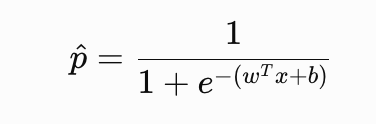

In [ ]:

# Import Pipeline to combine preprocessing and model training.
from sklearn.pipeline import Pipeline

# Import Logistic Regression, our classification algorithm.
from sklearn.linear_model import LogisticRegression

# Create a pipeline with two stages:
# 1. Transform numerical and categorical features.
# 2. Train the Logistic Regression classifier.
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,  # Allow enough iterations for convergence.
        random_state=42
    ))
])

print("Logistic Regression pipeline created.")


**Why use a pipeline?**
- Ensures training and inference use the same preprocessing.
- Prevents test data from influencing the fitted preprocessing transformations.
- Keeps the workflow reproducible and easier to deploy.

In [ ]:
# 6.2 Build and train the model using the actual x1...x23 dataset columns.
# Keep these names consistent with X and the deployed Streamlit application.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_features = ["x2", "x3", "x4", "x6", "x7", "x8", "x9", "x10", "x11"]
numerical_features = [column for column in X.columns if column not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)
print("Model training completed successfully.")
print("Training feature order:", list(X_train.columns))


***What does fit() do?***
1. Learns the scaling parameters from numerical training features.
2. Learns the categorical encoding from training features.
3. Estimates Logistic Regression coefficients by optimizing its loss function.

The optimizer seeks coefficients that minimize the regularized logistic loss. Scikit-learn's default Logistic Regression uses L2 regularization unless configured otherwise.

In [ ]:
# 6.3 Generate predictions

# Predict the class label for each test observation.
y_pred = model.predict(X_test)

# Predict the probability of class 1 (default).
# Column 0 represents class 0; column 1 represents class 1.
y_prob = model.predict_proba(X_test)[:, 1]

# Display a few actual and predicted values.
results = pd.DataFrame({
    "Actual": y_test.to_numpy()[:10],
    "Predicted": y_pred[:10],
    "Default Probability": y_prob[:10]
})

display(results.round(3))


***Why generate both outputs?***
- predict() produces class labels using the model's default decision threshold.
- predict_proba() produces estimated probabilities, which let us evaluate alternative thresholds and ranking performance.

In [ ]:
# 6.4 Check model convergence

# Retrieve the trained Logistic Regression estimator
# from the final pipeline stage.
classifier = model.named_steps["classifier"]

# Display the number of optimization iterations used.
print("Iterations used:", classifier.n_iter_)

# Check whether the maximum iteration limit was reached.
if classifier.n_iter_.max() < classifier.max_iter:
    print("Training finished before the iteration limit.")
else:
    print(
        "Check convergence warnings and solver diagnostics "
        "before proceeding."
    )


# ***Step 7 — Evaluate the Logistic Regression Model***

***Objective***:
- Measure how well our trained model predicts credit-card defaults on unseen test data.

In [ ]:
# 7.1 Calculate evaluation metrics

# Import the evaluation metrics from scikit-learn.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate accuracy: proportion of all predictions that are correct.
accuracy = accuracy_score(y_test, y_pred)

# Calculate precision: proportion of predicted defaults that are actual defaults.
precision = precision_score(y_test, y_pred, zero_division=0)

# Calculate recall: proportion of actual defaults detected by the model.
recall = recall_score(y_test, y_pred, zero_division=0)

# Calculate F1-score: harmonic mean of precision and recall.
f1 = f1_score(y_test, y_pred, zero_division=0)

# Calculate ROC-AUC using predicted probabilities, not class labels.
roc_auc = roc_auc_score(y_test, y_prob)

# Display all metrics in a readable format.
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")


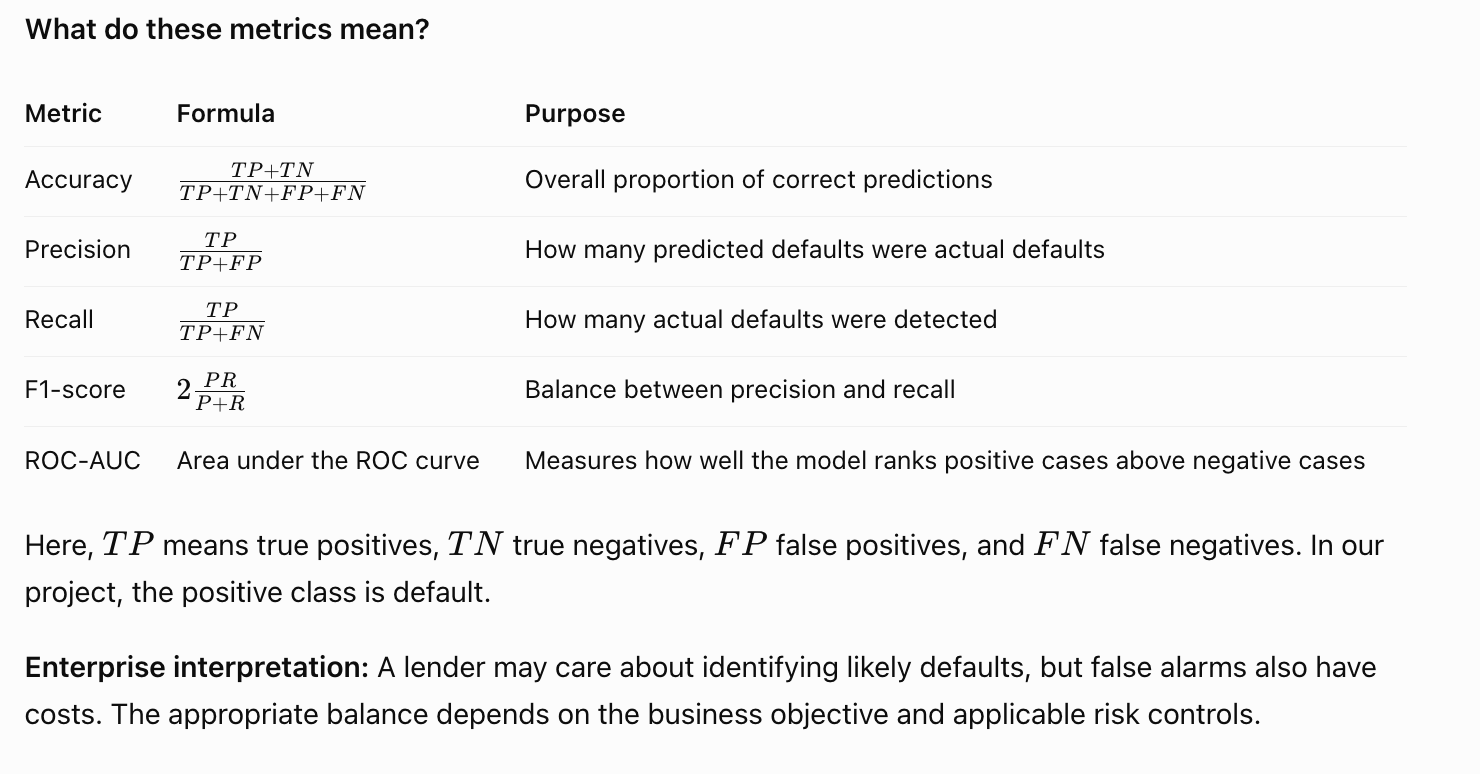

In [ ]:
# 7.2 Display the confusion matrix

# Import the confusion matrix visualization utility.
from sklearn.metrics import ConfusionMatrixDisplay

# Compare actual labels with predicted labels.
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Default", "Default"],
    cmap="Blues"
)

# Add a title to the visualization.
plt.title("Logistic Regression — Confusion Matrix")

# Display the chart.
plt.show()


The ***confusion matrix ***shows four outcomes:
- **True Negative (TN)**: correctly predicted no default.
- **False Positive (FP)**: predicted default, but no default occurred.
- **False Negative (FN)**: predicted no default, but default occurred.
- **True Positive (TP)**: correctly predicted default.
False negatives are especially important to analyze when the objective is to detect potential defaults.

In [ ]:
# 7.3 Plot the ROC curve


# Import the ROC curve visualization utility.
from sklearn.metrics import RocCurveDisplay

# Plot the ROC curve using actual labels and predicted probabilities.
RocCurveDisplay.from_predictions(y_test, y_prob)

# Add a descriptive title.
plt.title("ROC Curve — Logistic Regression")

# Display the chart.
plt.show()


The ***ROC curve*** compares the true positive rate against the false positive rate across different classification thresholds.
- A higher **ROC-AUC** generally indicates better ranking performance. It does not, by itself, establish that the predicted probabilities are well calibrated or that the model is suitable for production.

In [ ]:
# 7.4 Generate the classification report

# Display precision, recall, F1-score, and sample counts
# separately for each class.
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Default", "Default"],
        zero_division=0
    )
)


This report helps us compare ***performance*** for both classes rather than relying on a single aggregate metric.

# ***Step 8 — Interpret Logistic Regression Coefficients***

***Objective***:
- Understand how input features relate to the model's predicted default probability.

In [ ]:
# 8.1 Extract the coefficients

# Get the trained Logistic Regression estimator from the pipeline.
classifier = model.named_steps["classifier"]

# Get the feature names after preprocessing and encoding.
feature_names = model.named_steps["preprocessing"].get_feature_names_out()

# Extract the learned coefficients.
coefficients = classifier.coef_[0]

# Create a table of feature names and their coefficients.
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by absolute coefficient magnitude for inspection.
coef_df["Absolute Coefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(
    "Absolute Coefficient",
    ascending=False
)

# Display the features with the largest coefficient magnitudes.
display(coef_df.head(15).round(4))

**Why?**
- The coefficients are the weights learned by Logistic Regression. Their signs indicate the direction of association with the log-odds of default, holding other model inputs constant.

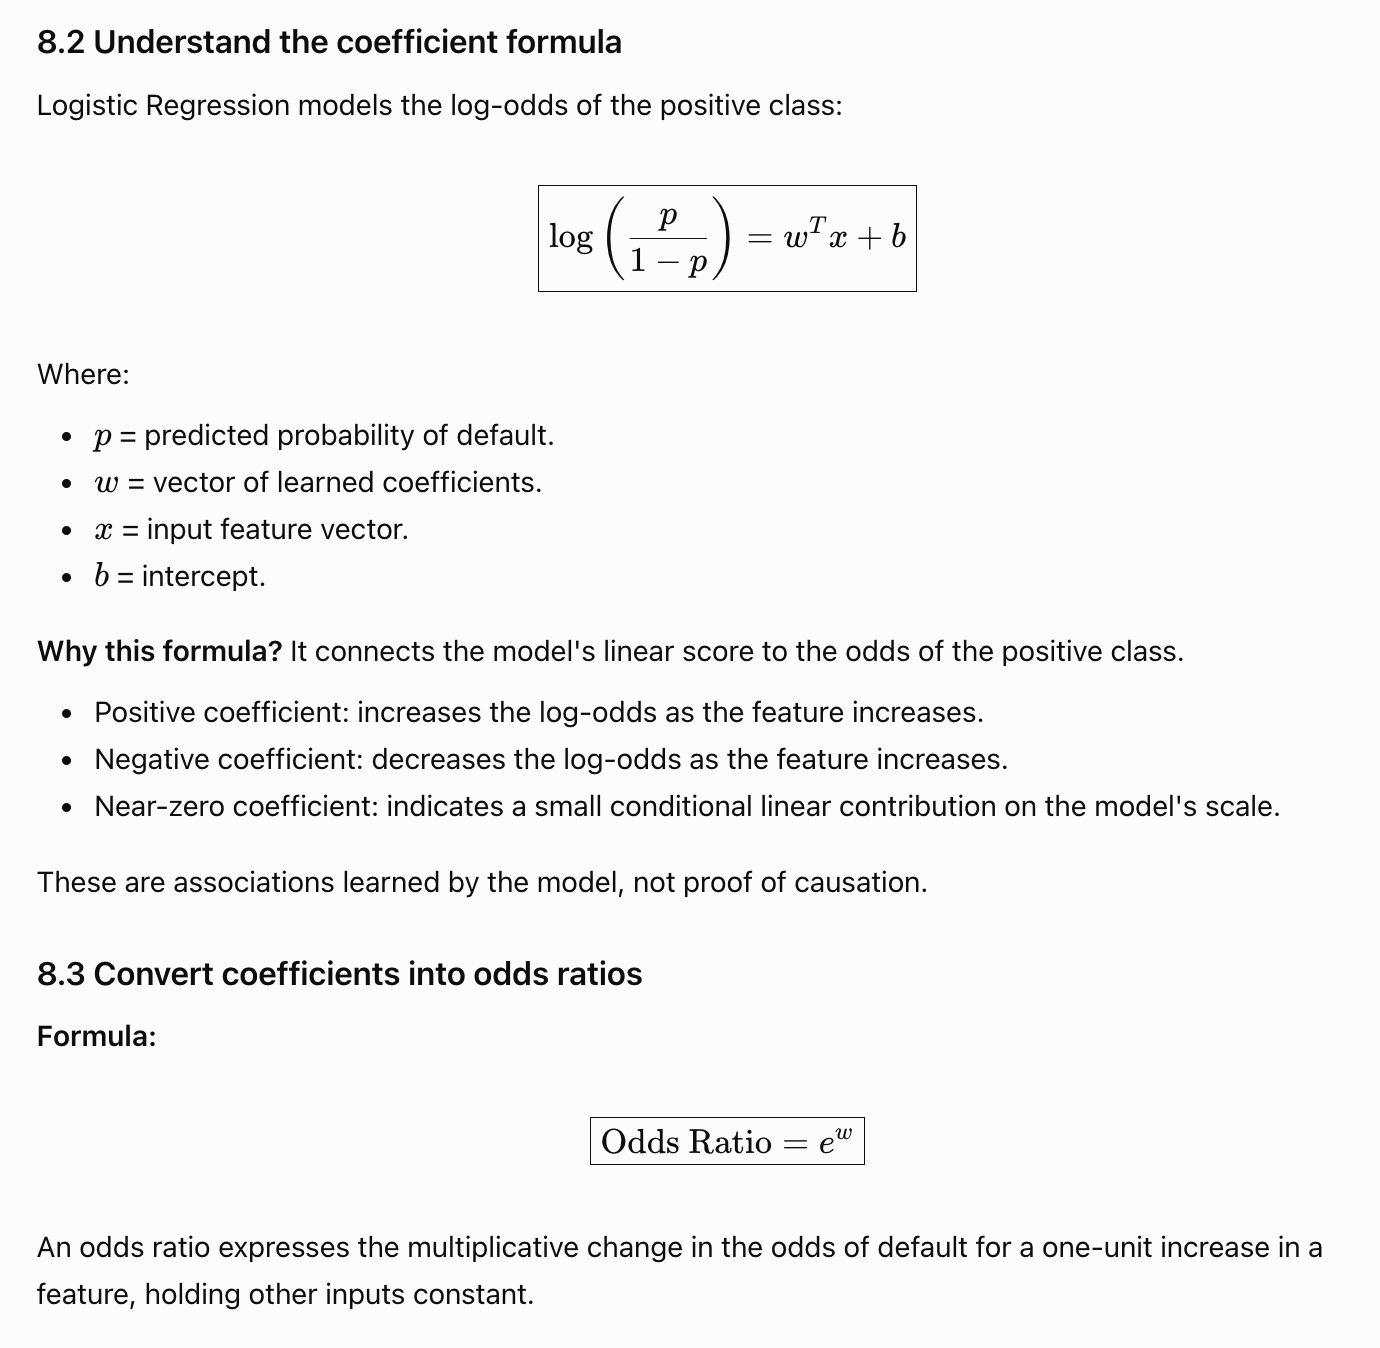

In [ ]:
# Calculate the odds ratio for each learned coefficient.
coef_df["Odds Ratio"] = np.exp(coef_df["Coefficient"])

# Display coefficients and odds ratios together.
display(
    coef_df[
        ["Feature", "Coefficient", "Odds Ratio"]
    ].head(15).round(4)
)

***Interpretation***:
- Odds ratio greater than 1: higher feature values are associated with higher odds.
- Odds ratio below 1: higher feature values are associated with lower odds.
- Odds ratio equal to 1: no change in odds for a one-unit increase.

Because our numerical features are standardized, a one-unit increase generally means a one-standard-deviation increase for those features—not one dollar or one year. **One-hot** encoded features require a separate category-aware interpretation.

In [ ]:
# 8.4 Visualize the coefficients
# Select the 15 features with the largest absolute coefficients.
top_features = coef_df.head(15).sort_values("Coefficient")

# Plot positive and negative coefficient values.
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

# The vertical reference at zero separates positive and negative values.
plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Largest Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

This chart shows the **direction** and **magnitude** of the selected ***coefficients***.
- Coefficient magnitude alone does not establish feature importance, particularly when features are correlated.

# ***Step 9 — Decision Threshold Tuning***

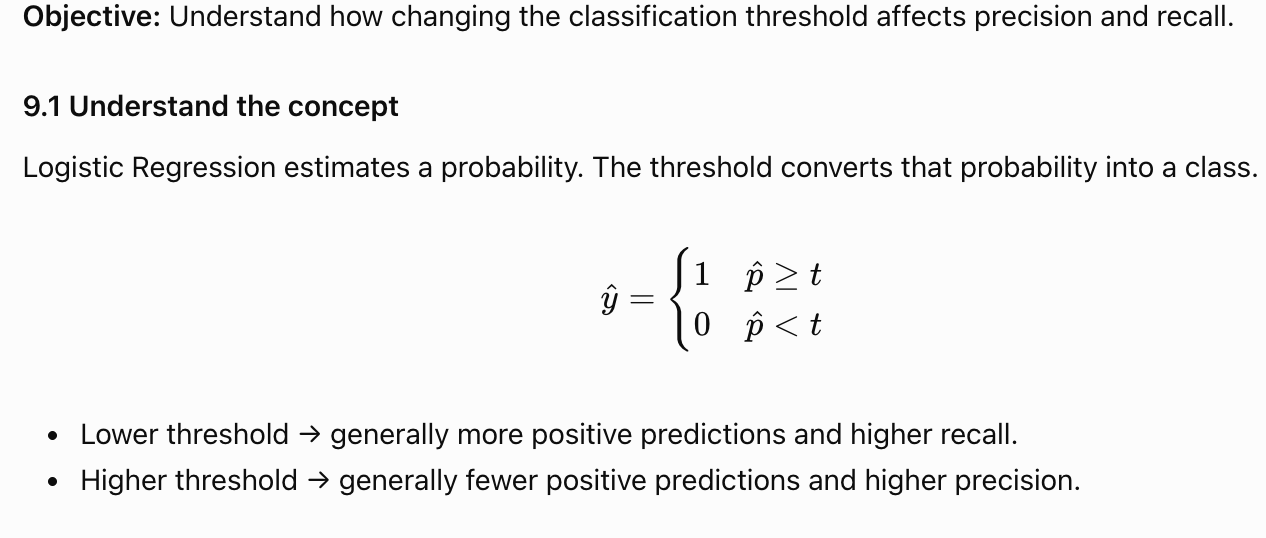

In [ ]:
# 9.2 Create a validation set
# We should tune the threshold using validation data, not the test set. This keeps our final test evaluation independent.

# Split the existing training data into a smaller training
# set and a validation set for threshold selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a separate pipeline for threshold experiments.
threshold_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train only on the smaller training subset.
threshold_model.fit(X_fit, y_fit)

# Estimate default probabilities on validation data.
val_probabilities = threshold_model.predict_proba(X_val)[:, 1]

print("Validation probabilities generated.")

In [ ]:
# 9.3 Compare different thresholds

# Import the metrics needed to compare thresholds.
from sklearn.metrics import precision_score, recall_score, f1_score

# Define candidate thresholds for experimentation.
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

results = []

for threshold in thresholds:
    # Convert probabilities into binary class predictions.
    val_predictions = (
        val_probabilities >= threshold
    ).astype(int)

    # Calculate the metrics at this threshold.
    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, val_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_predictions, zero_division=0
        )
    })

# Display the comparison table.
threshold_results = pd.DataFrame(results)
display(threshold_results.round(3))

In [ ]:
# 9.4 Visualize the results

# Plot how precision, recall, and F1-score vary with threshold.
threshold_results.set_index("Threshold")[
    ["Precision", "Recall", "F1-score"]
].plot(marker="o", figsize=(9, 5))

plt.title("Validation Metrics Across Decision Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

***Important***:
- We should not automatically choose the **threshold** with the highest F1-score.
- In an enterprise setting, **threshold** selection should reflect business costs, acceptable false-positive rates, recall requirements, and any applicable policy constraints.

- For this project, we will choose a **threshold** based on an explicitly documented validation criterion. We will then retrain on the full training set and evaluate once on the held-out test set.

# ***Step 10 — Finalize and Save the Logistic Regression Model***

***Objective***:
- Select the decision threshold using validation data, retrain the model on the complete training set, evaluate it on the untouched test set, and save the complete preprocessing-and-model pipeline.

In [ ]:
# 10.1 Select the threshold

# Identify the row with the highest validation F1-score.
best_row = threshold_results.loc[
    threshold_results["F1-score"].idxmax()
]

# Store the selected decision threshold.
best_threshold = float(best_row["Threshold"])

# Display the selected threshold and validation metrics.
print("Selected threshold:", best_threshold)
print("Validation precision:", round(best_row["Precision"], 3))
print("Validation recall:", round(best_row["Recall"], 3))
print("Validation F1-score:", round(best_row["F1-score"], 3))

**Why**?
- We select the threshold using validation data rather than the test set to avoid tuning our decision rule against the final evaluation results.

In [ ]:
# 10.2 Retrain on the complete training set

# Create the final pipeline using the same preprocessing
# and Logistic Regression configuration.
final_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Fit the final pipeline on all training observations.
# The test set remains untouched.
final_model.fit(X_train, y_train)

print("Final model trained successfully.")

***Why?***
- After selecting the threshold, we use the full training set to estimate the final model parameters. The preprocessing transformations are also fitted again on the full training data.

In [ ]:
# 10.3 Evaluate on the test set

# Estimate the probability of default for test observations.
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data.
test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Calculate final test metrics.
print("Final test evaluation")
print("---------------------")
print("Accuracy:", round(
    accuracy_score(y_test, test_predictions), 3
))
print("Precision:", round(
    precision_score(y_test, test_predictions, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, test_predictions, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, test_predictions, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, test_probabilities), 3
))

***10.4 Save the complete pipeline***

In [ ]:
# 10.4 Save the complete model pipeline, threshold, and UI validation metadata.
# Run this cell after final_model and best_threshold have been created.

import json
import joblib

# Keep the raw feature names required by the fitted pipeline.
feature_names = list(X_train.columns)

# Human-readable mapping for the original Taiwan credit-card dataset.
feature_schema = {
    "x1":  {"label": "Credit limit (LIMIT_BAL)", "description": "Assigned credit limit. Values are in the dataset's original units.", "kind": "numeric", "section": "Customer profile"},
    "x2":  {"label": "Sex (SEX)", "description": "Dataset category code: 1 or 2. This is a historical dataset field.", "kind": "categorical", "section": "Customer profile"},
    "x3":  {"label": "Education (EDUCATION)", "description": "Encoded education category. Use only codes observed in the training data.", "kind": "categorical", "section": "Customer profile"},
    "x4":  {"label": "Marital status (MARRIAGE)", "description": "Encoded marital-status category. Use only codes observed in the training data.", "kind": "categorical", "section": "Customer profile"},
    "x5":  {"label": "Age (AGE)", "description": "Age recorded in years.", "kind": "numeric", "section": "Customer profile"},
    "x6":  {"label": "Most recent repayment status (PAY_0)", "description": "Repayment-status code for the most recent month; this is an encoded category, not a continuous measurement.", "kind": "categorical", "section": "Repayment history"},
    "x7":  {"label": "Repayment status — 2 months ago (PAY_2)", "description": "Recorded repayment-status code.", "kind": "categorical", "section": "Repayment history"},
    "x8":  {"label": "Repayment status — 3 months ago (PAY_3)", "description": "Recorded repayment-status code.", "kind": "categorical", "section": "Repayment history"},
    "x9":  {"label": "Repayment status — 4 months ago (PAY_4)", "description": "Recorded repayment-status code.", "kind": "categorical", "section": "Repayment history"},
    "x10": {"label": "Repayment status — 5 months ago (PAY_5)", "description": "Recorded repayment-status code.", "kind": "categorical", "section": "Repayment history"},
    "x11": {"label": "Repayment status — 6 months ago (PAY_6)", "description": "Recorded repayment-status code.", "kind": "categorical", "section": "Repayment history"},
    "x12": {"label": "Bill statement — month 1 (BILL_AMT1)", "description": "Statement balance for month 1, in the dataset's original units.", "kind": "numeric", "section": "Bill statements"},
    "x13": {"label": "Bill statement — month 2 (BILL_AMT2)", "description": "Statement balance for month 2, in the dataset's original units.", "kind": "numeric", "section": "Bill statements"},
    "x14": {"label": "Bill statement — month 3 (BILL_AMT3)", "description": "Statement balance for month 3, in the dataset's original units.", "kind": "numeric", "section": "Bill statements"},
    "x15": {"label": "Bill statement — month 4 (BILL_AMT4)", "description": "Statement balance for month 4, in the dataset's original units.", "kind": "numeric", "section": "Bill statements"},
    "x16": {"label": "Bill statement — month 5 (BILL_AMT5)", "description": "Statement balance for month 5, in the dataset's original units.", "kind": "numeric", "section": "Bill statements"},
    "x17": {"label": "Bill statement — month 6 (BILL_AMT6)", "description": "Statement balance for month 6, in the dataset's original units.", "kind": "numeric", "section": "Bill statements"},
    "x18": {"label": "Payment amount — month 1 (PAY_AMT1)", "description": "Payment amount recorded for month 1, in the dataset's original units.", "kind": "numeric", "section": "Payment history"},
    "x19": {"label": "Payment amount — month 2 (PAY_AMT2)", "description": "Payment amount recorded for month 2, in the dataset's original units.", "kind": "numeric", "section": "Payment history"},
    "x20": {"label": "Payment amount — month 3 (PAY_AMT3)", "description": "Payment amount recorded for month 3, in the dataset's original units.", "kind": "numeric", "section": "Payment history"},
    "x21": {"label": "Payment amount — month 4 (PAY_AMT4)", "description": "Payment amount recorded for month 4, in the dataset's original units.", "kind": "numeric", "section": "Payment history"},
    "x22": {"label": "Payment amount — month 5 (PAY_AMT5)", "description": "Payment amount recorded for month 5, in the dataset's original units.", "kind": "numeric", "section": "Payment history"},
    "x23": {"label": "Payment amount — month 6 (PAY_AMT6)", "description": "Payment amount recorded for month 6, in the dataset's original units.", "kind": "numeric", "section": "Payment history"},
}

metadata = {
    "model_name": "Credit Card Default Prediction",
    "model_version": "1.0.0",
    "target_name": "default_payment_next_month",
    "positive_class": 1,
    "threshold": float(best_threshold),
    "feature_names": feature_names,
    "categorical_features": categorical_features,
    "features": {}
}

for feature in feature_names:
    series = X_train[feature].dropna()
    entry = dict(feature_schema.get(feature, {
        "label": feature, "description": "Input feature from the training dataset.",
        "kind": "numeric", "section": "Other features"
    }))
    entry["min"] = float(series.min())
    entry["max"] = float(series.max())
    entry["median"] = float(series.median())
    if feature in categorical_features:
        entry["categories"] = sorted([int(v) if float(v).is_integer() else float(v) for v in series.unique()])
    metadata["features"][feature] = entry

joblib.dump(final_model, "logistic_regression_pipeline.joblib")
joblib.dump(float(best_threshold), "decision_threshold.joblib")
with open("model_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False)

print("Saved: logistic_regression_pipeline.joblib")
print("Saved: decision_threshold.joblib")
print("Saved: model_metadata.json")
print("Feature count:", len(feature_names))


***Why save the pipeline?***
- It preserves the fitted encoders, scaler, and Logistic Regression model together.
- The deployed application can then apply exactly the same transformations used during training.
- `model_metadata.json` contains feature labels, descriptions, categories, and training-set ranges for the UI.


***10.5 Download the model artifacts from Colab***

In [ ]:
# Download all artifacts needed by the Streamlit app.
from google.colab import files

files.download("logistic_regression_pipeline.joblib")
files.download("decision_threshold.joblib")
files.download("model_metadata.json")


# ***Step 11 — Finalize and Validate the Google Colab Notebook***

**Objective**:
- Ensure our Logistic Regression notebook is reproducible, properly documented, and ready to publish on GitHub.
- We will keep the complete model-development workflow in one notebook: `logistic_regression.ipynb`.


# Final Project Summary

## Problem
Predict next-month credit-card default using historical client data.

## Dataset
[UCI Default of Credit Card Clients dataset.](https://archive.ics.uci.edu/dataset/350/defaultofcreditcardclients)

## Algorithm
Logistic Regression — Binary Classification.

## Workflow
1. Data loading and exploration
2. Exploratory Data Analysis
3. Feature and target separation
4. Train/validation/test split
5. Feature preprocessing
6. Logistic Regression training
7. Model evaluation
8. Coefficient interpretation
9. Decision threshold selection
10. Final model training and serialization

## Evaluation
The final test metrics are calculated in the notebook.
No performance values are assumed in advance.

## Limitations
- Historical associations do not establish causation.
- Performance may change on new populations or over time.
- Threshold selection depends on business objectives.
- This educational model is not approved for real lending decisions.

## Reproducibility
The notebook uses fixed random seeds and a preprocessing pipeline.


In [ ]:
# 11.2 Verify the final model and threshold


# Confirm that the final pipeline contains both required stages.
assert "preprocessing" in final_model.named_steps
assert "classifier" in final_model.named_steps

# Confirm that the threshold is within the valid probability range.
assert 0 <= best_threshold <= 1

# Confirm that the model can produce probabilities for test records.
probability_check = final_model.predict_proba(X_test.iloc[:5])

# Each row should contain probabilities for both binary classes.
assert probability_check.shape == (5, 2)

# Confirm that each pair of probabilities sums approximately to 1.
assert np.allclose(probability_check.sum(axis=1), 1.0)

print("Model validation checks passed.")


In [ ]:
# Print the Python and library versions used to train the model.
import sys
import sklearn
import numpy
import scipy
import pandas
import joblib

print("Python:", sys.version)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Pandas:", pandas.__version__)
print("Joblib:", joblib.__version__)

In [ ]:
import sklearn
import sys

print("Python version:", sys.version)
print("scikit-learn version:", sklearn.__version__)

In [ ]:
import numpy as np
import scipy
import joblib

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)
print("joblib:", joblib.__version__)